# 1. Change Current Directory

In [1]:
import os
import sys

project_root = os.path.abspath(os.path.join(os.getcwd(), '..'))

if project_root not in sys.path:
    sys.path.append(project_root)

print("Project root added to sys.path:", project_root)

Project root added to sys.path: e:\new_world\projects\rag-engine


## 2. Configure API Keys

In [ ]:
import os

from dotenv import load_dotenv

from app.core.config import get_settings

settings = get_settings()
load_dotenv()

print("API_KEY configured:", bool(settings.llm_api_key))
print("TAVILY_API_KEY configured:", bool(settings.tavily_api_key))
print("PINECONE_API_KEY configured:", bool(settings.pinecone_api_key))

API_KEY configured: True
TAVILY_API_KEY configured: True
PINECONE_API_KEY configured: True


## 5. Create Embeddings


In [ ]:
from langchain_openai import OpenAIEmbeddings

embeddings = OpenAIEmbeddings(
        model=settings.embed_model,
        base_url=settings.embed_base_url,
        api_key=settings.embed_api_key,
        dimensions=1024,
    )

sample_vector = embeddings.embed_query("What is Agentic RAG?")
print("Embedding dimensions:", len(sample_vector))

Embedding dimensions: 1024


In [4]:
# sample_vector

## 6. Create the Pinecone Vector Database



The embedding model used in this notebook produces **1024-dimensional vectors**, so the Pinecone index must use dimension `1024`.


In [5]:
# Load Existing Index

from langchain_pinecone import PineconeVectorStore
from pinecone import Pinecone

INDEX_NAME = "industry-agentic-rag-kb"
NAMESPACE = "langgraph-agentic-rag"

# Connect to Pinecone
pc = Pinecone(api_key=os.environ["PINECONE_API_KEY"])

# Load existing Pinecone index
index = pc.Index(INDEX_NAME)

# Connect existing index with LangChain
vectorstore = PineconeVectorStore(
    index=index,
    embedding=embeddings,
    namespace=NAMESPACE,
)

# Create retriever
retriever = vectorstore.as_retriever(
    search_kwargs={
        "k": 4,
        "namespace": NAMESPACE,
    }
)

print("Existing Pinecone index loaded:", INDEX_NAME)

e:\new_world\projects\rag-engine\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Existing Pinecone index loaded: industry-agentic-rag-kb


## 7. Test Private KB Retrieval

In [6]:
test_question = "What happens if retrieved documents are not relevant in Agentic RAG?"

kb_docs = retriever.invoke(test_question)

for i, doc in enumerate(kb_docs, 1):
    print(f"\n--- KB RESULT {i} ---")
    print("Source:", doc.metadata.get("source"))
    print(doc.page_content[:700])


--- KB RESULT 1 ---
Source: https://docs.langchain.com/oss/python/langgraph/agentic-rag
APIFunctional APIAdditional resourcesUse docs programmaticallyLangChain AcademyCase studiesGet helpOn this pageConceptsSetupSet up LangSmithPreprocess documentsCreate a retriever toolGenerate a query or respondGrade documentsRewrite the questionGenerate an answerAssemble the graphRun the agentic RAGSee alsoTutorialsLangGraphBuild a custom RAG agent with LangGraphCopy pageCopy pageBuild a custom retrieval agent with LangGraph that decides when to search a vector store or respond directly.Copy pageCopy pageBuild a retrieval agent with LangGraph that decides when to search a vector store versus answering the user directly.

--- KB RESULT 2 ---
Source: https://docs.langchain.com/oss/python/langgraph/agentic-rag
Fetch and preprocess documents for retrieval.
Index those documents for semantic search and create a retriever tool for the agent.
Build an agentic RAG system that can decide when to use the ret

## 8. Initialize models

In [ ]:
from langchain_openai import ChatOpenAI

llm = ChatOpenAI(
    model=settings.llm_model,
    base_url=settings.llm_base_url,
    api_key=settings.llm_api_key,   
    temperature=0,
)
print(llm.invoke("Explain Agentic RAG in one sentence.").content)

**Agentic RAG is a retrieval-augmented generation system that uses an autonomous AI agent to dynamically plan, execute, and iterate on multi-step search, tool-use, and reasoning tasks—rather than performing a single, static retrieval pass—to answer complex queries.**


In [ ]:
from langchain_typesafe import Noul, TypeSafeClassifier

classifier = TypeSafeClassifier(
	api_key=settings.jev_api_key,
    base_url=settings.jev_base_url,
    model=settings.jev_model
)

result = classifier.invoke({
	"state": "This is a test message to verify the connection.",
	"questions": {
		"is_test": Noul(instructions="Is this message a test?")
	}
})

print(result)

C:\Users\Technomowj\AppData\Local\Temp\ipykernel_17224\2928762277.py:4: LangChainBetaWarning: The class `TypeSafeClassifier` is in beta. It is actively being worked on, so the API may change.
  classifier = TypeSafeClassifier(


model='typesafe/jev-1.13-20260917' answers={'is_test': NoulAnswer(type='noul', noul=0.99)} usage=Usage(input_tokens=282, output_tokens=21) request_id=None


## 9. Initialize Tavily Web Search

Tavily will be used only when the private knowledge base is insufficient.

This is important because we do not want to send every private/company question to the public web.

In [9]:
from langchain_tavily import TavilySearch

web_search = TavilySearch(
    max_results=5,
    topic="general",
    include_answer=True,
    include_raw_content=False,
)

print("Tavily search tool ready.")

Tavily search tool ready.


## 10. Define Structured Decisions

We need reliable yes/no or route outputs from the LLM.

Structured outputs help avoid parsing messy natural language.

In [ ]:
from typing import Annotated, Literal

from langchain_core.documents import Document
from langchain_core.messages import AIMessage, BaseMessage, HumanMessage
from langgraph.graph.message import add_messages
from typing_extensions import TypedDict


class AgentState(TypedDict):
    messages: Annotated[list[BaseMessage], add_messages]
    
    question: str
    current_query: str
    kb_docs: list[Document]
    web_results: str
    kb_grade: str
    web_grade: str
    answer: str
    source_used: str
    retry_count: int
    rewrite_history: list[str]

In [11]:
def format_history(messages: list[BaseMessage]) -> str:
    if not messages:
        return "No previous conversation."
    
    history_text = ""
    for msg in messages:
        role = "User" if isinstance(msg, HumanMessage) else "AI"
        history_text += f"{role}: {msg.content}\n"
    return history_text

## 11. Node 1 — Route the Question

In [12]:
from langchain_typesafe import Choice


def route_question_jev(state: AgentState):
    question = state["question"]
    
    # تاریخچه را بدون پیام فعلی کاربر می‌گیریم
    # چون پیام فعلی همان question است و تکرار آن در history باعث سردرگمی Jev می‌شود
    history_messages = state["messages"][:-1]
    history = format_history(history_messages) if history_messages else "No previous conversation."
    
    # به Jev هم تاریخچه را می‌دهیم، هم سوال فعلی را
    result = classifier.invoke({
        "state": (
            f"Conversation History:\n{history}\n\n"
            f"Current User Question:\n{question}"
        ),
        "questions": {
            "route": Choice(
                instructions="Which path should this user question take, considering the conversation history?",
                criteria={
                    "kb": (
                        "Any factual question that requires retrieving information, "
                        "especially questions about Agentic RAG, LangGraph, retrieval grading, "
                        "query rewriting, RAG architecture, retriever tools, or web fallback. "
                        "Also route general knowledge questions here so the system can verify them. "
                        "If the question contains a pronoun (it, its, they, them, that, this) "
                        "but the conversation history CLEARLY indicates the topic, still route to kb."
                    ),
					"direct": (
						"Use this for TWO categories ONLY: "
						
						"(1) Simple greetings, thanks, or very brief chit-chat "
						"(e.g., 'Hello', 'How are you', 'Thanks', 'Good morning'). "
						
						"(2) History-only requests that refer to the PREVIOUS conversation "
						"and can be answered PURELY from the conversation history, WITHOUT "
						"needing any new information from the KB or web. "
						"Key signal: the question contains words like 'that', 'it', 'your previous answer', "
						"'what you said', 'point 2', 'the first one', 'rephrase', 'summarize', 'expand', "
						"'give me an example of THAT', 'tell me more about IT', etc. "
						"Examples: "
						"'summarize that', "
						"'summarize your previous answer', "
						"'explain what you meant by X', "
						"'expand on point 2', "
						"'give me an example of that', "
						"'repeat that', "
						"'can you rephrase that', "
						"'what did you say about X', "
						"'remind me what you said about Y', "
						"'translate that to French'. "
						
						"Do NOT use this for NEW factual questions that require looking up "
						"new information from the KB or the web (e.g., 'what is LangGraph?', "
						"'what is the latest version of X?'). "
						"Do NOT use this in the FIRST turn if the user asks to summarize or refer "
						"to previous conversation (there is no history yet — route to kb instead)."
					),
                    "clarify": (
                        "The question is ambiguous OR contains unresolved pronouns that CANNOT be resolved "
                        "from the conversation history. "
                        "IMPORTANT: If the history clearly indicates the subject, do NOT use clarify - use kb instead. "
                        "Only use clarify when the history does NOT provide enough context to understand the question."
                    )
                }
            )
        }
    })

    decision = result.choices["route"].choice
    confidence = result.choices["route"].confidence
    print(f"[Router] {decision} (confidence: {confidence:.3f})")

    return {
        "current_query": question,
        "source_used": decision,
    }

def route_after_router(state: AgentState) -> Literal["retrieve_kb", "direct_answer", "clarify_question"]:
    if state["source_used"] == "kb":
        return "retrieve_kb"
    elif state["source_used"] == "clarify":
        return "clarify_question"
    return "direct_answer"

# new node 1

In [13]:
from langgraph.types import interrupt


def clarify_question(state: AgentState):
    question = state["question"]
    history = format_history(state["messages"])
    
    clarification_text = llm.invoke(f'''
    The user's question is ambiguous or lacks context. 
    Ask a short, specific clarifying question to get the missing information.
    Do not answer the question, only ask for clarification.
    
    Conversation History:
    {history}
    
    User's question: {question}
    Clarifying question:''').content

    # توقف گراف و منتظر ماندن برای پاسخ کاربر
    user_response = interrupt(clarification_text)

    combined_question = f"Original question: {question}\nUser's clarification: {user_response}"
    
    return {
        "current_query": combined_question,
        "source_used": "kb_after_clarification",
        # اضافه کردن پاسخ کاربر به تاریخچه
        "messages": [HumanMessage(content=user_response)] 
    }

## 12. Node 2 — Retrieve from the Private KB

In [14]:
def retrieve_kb(state: AgentState):
    query = state["current_query"]
    docs = retriever.invoke(query)

    print(f"[KB Retriever] Query: {query}")
    print(f"[KB Retriever] Retrieved: {len(docs)} chunks")

    return {"kb_docs": docs}

## 13. Node 3 — Grade Private KB Evidence

This is the key step that decides whether we can answer from the private KB or need web fallback.

In [15]:
# --- Grade KB ---
def grade_kb_evidence_jev(state: AgentState):
    question = state["question"]
    
    context = "\n\n".join(
        f"Source: {doc.metadata.get('source')}\n{doc.page_content}"
        for doc in state["kb_docs"]
    )
    
    result = classifier.invoke({
        "state": f"Question:\n{question}\n\nPrivate KB evidence:\n{context}",
        "questions": {
            "good_enough": Noul(
                instructions="Does this private KB evidence contain useful and relevant information to help answer the question?"
            )
        }
    })
    
    probability = result.nouls["good_enough"].noul
    THRESHOLD = 0.80 
    grade_label = "good" if probability >= THRESHOLD else "weak"
    print(f"[KB Grader] Probability: {probability:.3f} -> {grade_label}")
    
    return {"kb_grade": grade_label}

MAX_REWRITES = 2

def decide_after_kb_grade(state: AgentState) -> Literal["generate_from_kb", "rewrite_query", "search_web"]:
    if state["kb_grade"] == "good":
        return "generate_from_kb"
    
    # اگر ضعیف بود، اول سعی در بازنویسی سوال می‌کنیم
    if state["retry_count"] < MAX_REWRITES:
        return "rewrite_query"
        
    # اگر بعد از چند بار بازنویسی هنوز ضعیف بود، می‌رویم سراغ وب
    return "search_web"


## 14. Node 4 — Tavily Web Search Fallback

This node runs only when the private KB evidence is weak.

We search the web using the original question, or the current rewritten query if a rewrite already happened.

In [16]:
def search_web(state: AgentState):
    query = state["current_query"]

    print(f"[Tavily Search] Query: {query}")

    result = web_search.invoke({"query": query})

    # Tavily can return dict/list structures depending on package version.
    # Convert it into readable text for grading and generation.
    if isinstance(result, dict):
        answer = result.get("answer", "")
        results = result.get("results", [])
        lines = []
        if answer:
            lines.append(f"Tavily answer: {answer}")

        for item in results:
            title = item.get("title", "")
            url = item.get("url", "")
            content = item.get("content", "")
            lines.append(f"Title: {title}\nURL: {url}\nContent: {content}")

        web_text = "\n\n".join(lines) if lines else str(result)
    else:
        web_text = str(result)

    print("[Tavily Search] Result characters:", len(web_text))

    return {
        "web_results": web_text,
        "source_used": "web",
    }

## 15. Node 5 — Grade Web Evidence

In [17]:
# --- Grade Web (بدون تغییر خاصی، فقط دیگر نیازی به Rewrite در این مرحله نیست) ---
def grade_web_evidence_jev(state: AgentState):
    question = state["question"]
    web_results = state["web_results"]
    
    result = classifier.invoke({
        "state": f"Question:\n{question}\n\nWeb search evidence:\n{web_results}",
        "questions": {
            "good_enough": Noul(
                instructions=(
                    "Does this web evidence contain at least PARTIAL information "
                    "that could help answer the question, even if not complete? "
                    "For version numbers, dates, or specific facts, if the web result "
                    "mentions the requested item (even with different details), consider it useful. "
                    "Only say NO if the web results are completely unrelated to the question."
                )
            )
        }
    })
    
    probability = result.nouls["good_enough"].noul
    WEB_THRESHOLD = 0.5
    grade_label = "good" if probability >= WEB_THRESHOLD else "weak"
    print(f"[Web Grader] Probability: {probability:.3f} -> {grade_label}")
    
    return {"web_grade": grade_label}

def decide_after_web_grade(state: AgentState) -> Literal["generate_from_web", "answer_insufficient"]:
    if state["web_grade"] == "good":
        return "generate_from_web"
    return "answer_insufficient"

## 16. Node 6 — Rewrite the Query

If both KB and web evidence are weak, we rewrite once and then try the KB again.

Why back to KB first?

Because the rewritten query may help retrieve better private evidence before relying on web search again.

In [18]:
def rewrite_query(state: AgentState):
    question = state["question"]
    history = format_history(state["messages"])
    previous_attempts = state.get("rewrite_history", [])
    
    # تشخیص نوع: initial (قبل از KB) یا retry (بعد از weak grade)
    is_initial = state.get("kb_grade", "") == ""
    
    if is_initial:
        # ===== حالت اول: بازنویسی اولیه قبل از رفتن به KB =====
        retry_count = state.get("retry_count", 0)  # افزایش نمی‌یابد
        
        prompt = f'''
        Rewrite the user's question into a self-contained, search-friendly query.
        
        Rules:
        - If the question contains pronouns (it, its, they, them, that, this), 
          resolve them using the conversation history.
        - Make the question explicit and complete (mention the actual subject).
        - If the question includes a clarification prefix like 
          "Original question: X / User's clarification: Y", 
          merge them into one clean, natural question.
        - Keep the original intent.
        - Do NOT change the meaning if the question is already clear and self-contained.
        - Return ONLY the rewritten query, nothing else.
        
        Conversation History:
        {history}
        
        Current Question:
        {question}
        '''
        label = "Initial"
    else:
        # ===== حالت دوم: بازنویسی مجدد بعد از شکست KB =====
        retry_count = state["retry_count"] + 1
        
        if previous_attempts:
            attempts_text = "\n".join(f"- {a}" for a in previous_attempts)
        else:
            attempts_text = "None"
        
        prompt = f'''
        The previous search in the private KB failed to find good evidence.
        Rewrite the question to be concise and keyword-rich. Keep the original intent.
        
        Rules:
        - If the question contains pronouns, use the conversation history to resolve them.
        - DO NOT repeat any of these previous rewrite attempts:
        {attempts_text}
        - Use a DIFFERENT keyword strategy or phrasing from previous attempts.
        - Return ONLY the rewritten query, nothing else.
        
        Conversation History:
        {history}
        
        Current Question:
        {question}
        '''
        label = f"Retry {retry_count}"
    
    rewritten = llm.invoke(prompt).content.strip()
    print(f"[Rewriter - {label}] {rewritten}")
    
    return {
        "current_query": rewritten,
        "retry_count": retry_count,
        "rewrite_history": previous_attempts + [rewritten],
    }

## 17. Node 7 — Generate from Private KB

In [19]:
def generate_from_kb(state: AgentState):
    question = state["question"]
    history = format_history(state["messages"])
    
    context = "\n\n".join(
        f"[KB Source: {doc.metadata.get('source')}]\n{doc.page_content}"
        for doc in state["kb_docs"]
    )

    answer = llm.invoke(f'''
    You are a helpful AI assistant.
    Answer the user's question using ONLY the private KB context.
    
    Rules:
    - Use the Conversation History to understand the context of the user's question.
    - Do not invent unsupported details.
    - Mention that the answer is based on the private KB.
    
    Conversation History:
    {history}
    
    Current Question:
    {question}
    
    Private KB context:
    {context}
    ''').content

    return {
        "answer": answer,
        "source_used": "private_kb",
        # اضافه کردن پاسخ AI به تاریخچه
        "messages": [AIMessage(content=answer)] 
    }

## 18. Node 8 — Generate from Web Search

In [20]:
def generate_from_web(state: AgentState):
    question = state["question"]
    web_context = state["web_results"]
    history = format_history(state["messages"])  # دریافت تاریخچه مکالمه

    answer = llm.invoke(f'''
You are a helpful AI assistant.

The private KB was insufficient, so web search was used.
Answer the user's question using ONLY the web search context.

Rules:
- Use the Conversation History to understand the context of the user's question.
- Beginner-friendly explanation.
- Do not invent unsupported details.
- Mention that the answer is based on Tavily web search.
- Include source type: Web Search.
- If URLs are present in context, include the most useful URLs.

Conversation History:
{history}

Current Question:
{question}

Web search context:
{web_context}
''').content

    return {
        "answer": answer,
        "source_used": "web_search",
        "messages": [AIMessage(content=answer)],  # ثبت پاسخ AI در تاریخچه
    }

## 19. Node 9 — Direct Answer

In [21]:
def direct_answer(state: AgentState):
    question = state["question"]
    history = format_history(state["messages"])

    answer = llm.invoke(f'''
You are a helpful AI assistant responding primarily from CONVERSATION HISTORY.
You do NOT have access to a knowledge base or web search in this mode.

Your task is one of three:
(A) GREETING / SMALL TALK: If the user is greeting or making small talk 
    → respond naturally and briefly.
(B) HISTORY PROCESSING: If the user is asking you to do something with the 
    PREVIOUS conversation (summarize, rephrase, expand, clarify, translate, 
    remind, or reference a specific point, etc.)
    → do EXACTLY that using the information from the Conversation History.
(C) ILLUSTRATIVE EXAMPLES: If the user asks for a CONCRETE EXAMPLE of a 
    CONCEPT you previously mentioned (e.g., "give me an example of X", 
    "show me what Y looks like", "can you illustrate that")
    → you MAY construct a HYPOTHETICAL illustrative example, even if that 
    exact example was not in the history, provided you follow the 
    ILLUSTRATION RULES below.

CRITICAL RULES (FACTUAL ACCURACY):
- Do NOT invent FACTUAL information that contradicts or goes beyond the 
  Conversation History.
- Do NOT claim that a hypothetical example is real, factual, or from a source.
- If the user asks a NEW factual question whose answer is NOT in the history 
  (e.g., "what is the latest version of X?", "what does Y cost?", 
  "who is the CEO of Z?"), say politely:
  "I don't have that information in our conversation. 
   Could you ask me as a new question so I can search for it?"

ILLUSTRATION RULES (for task C only):
- You MUST clearly label any constructed example with a phrase such as 
  "For illustration purposes..." or "Here's a hypothetical example..."
- The example must be built ONLY from concepts already mentioned in the 
  Conversation History. Do NOT introduce new facts, entities, or claims 
  that were not in the history.
- The example is meant to CLARIFY an existing concept, not to ADD new 
  factual knowledge.
- If you cannot construct a meaningful example from the history alone, 
  say so honestly instead of inventing one.

OTHER RULES:
- If the user asks for a summary, produce a concise summary of what YOU said 
  earlier (and/or what they said), NOT a generic explanation of the topic.
- If the user asks about a specific point (e.g., "point 2", "the first one"), 
  reference or quote it directly from your previous answer.
- Do NOT repeat the entire previous answer verbatim unless explicitly asked to.
- Keep responses brief and focused on the user's request.

Conversation History:
{history}

Current Message:
{question}
''').content

    return {
        "answer": answer,
        "source_used": "direct",
        "messages": [AIMessage(content=answer)],
    }

## 20. Node 10 — Insufficient Evidence Answer

In [22]:
def answer_insufficient(state: AgentState):
    answer = (
        "I could not find enough reliable evidence in the private knowledge base "
        "or the web search results to answer this confidently. "
        "Please provide more specific documents or rephrase the question."
    )

    return {
        "answer": answer,
        "source_used": "insufficient_evidence",
        "messages": [AIMessage(content=answer)],  # ثبت پاسخ در تاریخچه
    }

## 21. Build the LangGraph Workflow



In [23]:
from langgraph.checkpoint.memory import MemorySaver
from langgraph.graph import END, START, StateGraph

workflow = StateGraph(AgentState)

# افزودن نودها
workflow.add_node("route_question", route_question_jev)
workflow.add_node("clarify_question", clarify_question) # نود جدید
workflow.add_node("retrieve_kb", retrieve_kb)
workflow.add_node("grade_kb_evidence", grade_kb_evidence_jev)
workflow.add_node("rewrite_query", rewrite_query)
workflow.add_node("search_web", search_web)
workflow.add_node("grade_web_evidence", grade_web_evidence_jev)
workflow.add_node("generate_from_kb", generate_from_kb)
workflow.add_node("generate_from_web", generate_from_web)
workflow.add_node("direct_answer", direct_answer)
workflow.add_node("answer_insufficient", answer_insufficient)

# تعریف یال‌ها
workflow.add_edge(START, "route_question")

# تغییر ۱: مسیر kb از Router حالا به rewrite_query می‌رود (نه مستقیم به retrieve_kb)
workflow.add_conditional_edges(
    "route_question",
    route_after_router,
    {
        "retrieve_kb": "rewrite_query",      # ← این خط تغییر کرد
        "direct_answer": "direct_answer",
        "clarify_question": "clarify_question",
    },
)


# تغییر ۲: بعد از شفاف‌سازی، ابتدا rewrite_query (نه مستقیم به retrieve_kb)
workflow.add_edge("clarify_question", "rewrite_query")  # ← این خط تغییر کرد

workflow.add_edge("retrieve_kb", "grade_kb_evidence")

# یال‌های شرطی بعد از Grade KB (حلقه بازنویسی اینجا اضافه شد)
workflow.add_conditional_edges(
    "grade_kb_evidence",
    decide_after_kb_grade,
    {
        "generate_from_kb": "generate_from_kb",
        "rewrite_query": "rewrite_query",
        "search_web": "search_web",
    },
)

# بازگشت از بازنویسی به جستجوی KB
workflow.add_edge("rewrite_query", "retrieve_kb")

workflow.add_edge("search_web", "grade_web_evidence")

# یال‌های شرطی بعد از Grade Web
workflow.add_conditional_edges(
    "grade_web_evidence",
    decide_after_web_grade,
    {
        "generate_from_web": "generate_from_web",
        "answer_insufficient": "answer_insufficient",
    },
)

workflow.add_edge("generate_from_kb", END)
workflow.add_edge("generate_from_web", END)
workflow.add_edge("direct_answer", END)
workflow.add_edge("answer_insufficient", END)

memory = MemorySaver()

app_jev = workflow.compile(checkpointer=memory)

print("Industry-style Agentic RAG graph (Multi-turn enabled) compiled.")

Industry-style Agentic RAG graph (Multi-turn enabled) compiled.


## 22. Visualize the Graph

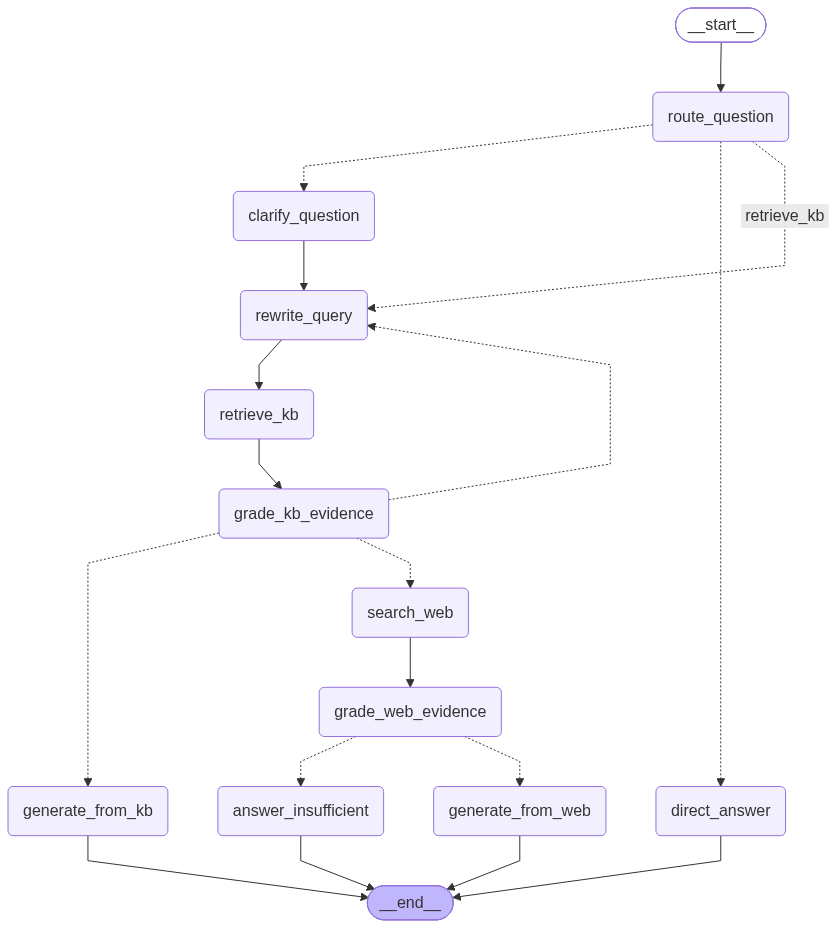

In [24]:
from IPython.display import Image, display

try:
    display(Image(app_jev.get_graph().draw_mermaid_png()))
except Exception as e:
    print("Graph visualization is optional. The graph can still run.")
    print("Reason:", e)

## 23. Helper Function

In [25]:
import uuid

from langgraph.types import Command


def chat_with_agent(user_input: str, thread_id: str = None):
    if thread_id is None:
        thread_id = str(uuid.uuid4())
        print(f"[New Session Started] Thread ID: {thread_id}")
    
    conf = {"configurable": {"thread_id": thread_id}}
    
    # وضعیت اولیه: همه فیلدهای موقت ریست می‌شوند
    input_state = {
        "question": user_input,
        "current_query": user_input,
        "kb_docs": [],
        "web_results": "",
        "kb_grade": "",
        "web_grade": "",
        "retry_count": 0,
        "rewrite_history": [],          # ← ریست حیاتی
        "messages": [HumanMessage(content=user_input)],
    }
    
    result = app_jev.invoke(input_state, config=conf)
    
    # حلقه while برای مدیریت Interruptهای پشت سر هم (نه فقط یکی)
    while "__interrupt__" in result:
        clarification_question = result["__interrupt__"][0].value
        print(f"\n🤖 Agent asks: {clarification_question}")
        
        user_clarification = input("👤 You: ")
        
        result = app_jev.invoke(
            Command(resume=user_clarification), 
            config=conf
        )
    
    print(f"\n🤖 Final Answer:\n{result['answer']}")
    return thread_id

In [26]:
import uuid

from langchain_core.messages import HumanMessage
from langgraph.types import Command


def run_conversation(
    scenario_name: str,
    turns: list,
    simulated_clarifications: dict = None,
):
    """
    یک مکالمه چندنوبتی را به صورت خودکار اجرا می‌کند.
    
    Args:
        scenario_name: نام سناریو برای نمایش در لاگ
        turns: لیست پیام‌های کاربر (هر المان = یک Turn)
        simulated_clarifications: دیکشنری که کلید آن شماره Turn (از 1) و مقدار آن پاسخ شبیه‌سازی‌شده کاربر است.
    """
    if simulated_clarifications is None:
        simulated_clarifications = {}

    thread_id = str(uuid.uuid4())
    conf = {"configurable": {"thread_id": thread_id}}
    
    print("\n" + "█" * 80)
    print(f"█ سناریو: {scenario_name}")
    print(f"█ Thread ID: {thread_id}")
    print("█" * 80)

    for turn_index, user_input in enumerate(turns, start=1):
        print(f"\n{'─' * 80}")
        print(f"🔹 Turn {turn_index} | 👤 User: {user_input}")
        print(f"{'─' * 80}")

        # --- وضعیت اولیه هر Turn (همه فیلدهای موقت ریست می‌شوند) ---
        input_state = {
			"question": user_input,
			"current_query": user_input,
			"kb_docs": [],
			"web_results": "",
			"kb_grade": "",
			"web_grade": "",
			"retry_count": 0,
			"rewrite_history": [],       # ← این خط را اضافه کنید
			"messages": [HumanMessage(content=user_input)],
		}

        result = app_jev.invoke(input_state, config=conf)

        # --- مدیریت Interruptها (ممکن است چندبار رخ دهد) ---
        interrupt_counter = 0
        while "__interrupt__" in result:
            clarification_q = result["__interrupt__"][0].value
            print(f"\n🤖 Agent asks: {clarification_q}")

            # پاسخ شبیه‌سازی‌شده را از دیکشنری برمی‌داریم، وگرنه یک پاسخ پیش‌فرض
            simulated_reply = simulated_clarifications.get(
                turn_index,
                "I am getting a Pinecone connection timeout error."
            )
            print(f"👤 Simulated User: {simulated_reply}")

            result = app_jev.invoke(
                Command(resume=simulated_reply),
                config=conf
            )
            interrupt_counter += 1

        # --- چاپ نتیجه نهایی این Turn ---
        print(f"\n🤖 Final Answer:\n{result.get('answer', 'N/A')}")
        print(f"\n📌 Source Used: {result.get('source_used', 'N/A')}")

    return thread_id

## 24. Demo 1 

In [27]:
# ─────────────────────────────────────────────────────────────
# سناریو ۱: شفاف‌سازی و ادامه مکالمه (Clarify & Resume)
# ─────────────────────────────────────────────────────────────
run_conversation(
    scenario_name="۱: Clarify & Resume (Interrupt Handling)",
    turns=[
        "How do I fix the error?",
    ],
    simulated_clarifications={
        1: "I am getting a Pinecone connection timeout error in my Python code.",
    },
)



████████████████████████████████████████████████████████████████████████████████
█ سناریو: ۱: Clarify & Resume (Interrupt Handling)
█ Thread ID: 76d89176-4de1-4824-85d4-5bb437d9b537
████████████████████████████████████████████████████████████████████████████████

────────────────────────────────────────────────────────────────────────────────
🔹 Turn 1 | 👤 User: How do I fix the error?
────────────────────────────────────────────────────────────────────────────────
[Router] clarify (confidence: 1.000)

🤖 Agent asks: What error are you encountering? Please share the exact error message or a description of what's happening.
👤 Simulated User: I am getting a Pinecone connection timeout error in my Python code.
[Rewriter - Initial] How do I fix a Pinecone connection timeout error in Python?
[KB Retriever] Query: How do I fix a Pinecone connection timeout error in Python?
[KB Retriever] Retrieved: 4 chunks
[KB Grader] Probability: 0.450 -> weak
[Rewriter - Retry 1] Troubleshooting Pinecone c

'76d89176-4de1-4824-85d4-5bb437d9b537'

## 25. Demo 2 

In [28]:
# ─────────────────────────────────────────────────────────────
# سناریو ۲: حافظه در تولید پاسخ (History in Generation)
# ─────────────────────────────────────────────────────────────
run_conversation(
    scenario_name="۲: History in Generation (Pronoun Resolution in Answer)",
    turns=[
        "What is Agentic RAG?",
        "What are its main components?",
        "Can you summarize them briefly?",
    ],
)


████████████████████████████████████████████████████████████████████████████████
█ سناریو: ۲: History in Generation (Pronoun Resolution in Answer)
█ Thread ID: cb773fdc-95ff-41ce-90b2-775b44267981
████████████████████████████████████████████████████████████████████████████████

────────────────────────────────────────────────────────────────────────────────
🔹 Turn 1 | 👤 User: What is Agentic RAG?
────────────────────────────────────────────────────────────────────────────────
[Router] kb (confidence: 1.000)
[Rewriter - Initial] What is Agentic RAG?
[KB Retriever] Query: What is Agentic RAG?
[KB Retriever] Retrieved: 4 chunks
[KB Grader] Probability: 0.930 -> good

🤖 Final Answer:
Based on the private KB, Agentic RAG is a custom retrieval agent built with LangGraph that decides when to search a vector store or respond directly to the user. It assembles a graph of steps (such as grading documents, rewriting the question, and generating an answer) to handle the retrieval and generation p

'cb773fdc-95ff-41ce-90b2-775b44267981'

## 26. Demo 3

In [29]:
# ─────────────────────────────────────────────────────────────
# سناریو ۳: حافظه در بازنویسی سوال (History in Rewriter)
# ─────────────────────────────────────────────────────────────
run_conversation(
    scenario_name="۳: History in Rewriter (Ambiguous Follow-up Query)",
    turns=[
        "Explain document grading in Agentic RAG.",
        "How do I fix it when it fails?",
    ],
)


████████████████████████████████████████████████████████████████████████████████
█ سناریو: ۳: History in Rewriter (Ambiguous Follow-up Query)
█ Thread ID: b9194576-ef81-43cd-ab21-69f10fd424ba
████████████████████████████████████████████████████████████████████████████████

────────────────────────────────────────────────────────────────────────────────
🔹 Turn 1 | 👤 User: Explain document grading in Agentic RAG.
────────────────────────────────────────────────────────────────────────────────
[Router] kb (confidence: 1.000)
[Rewriter - Initial] Explain document grading in Agentic RAG.
[KB Retriever] Query: Explain document grading in Agentic RAG.
[KB Retriever] Retrieved: 4 chunks
[KB Grader] Probability: 0.960 -> good

🤖 Final Answer:
Based on the private KB, document grading in Agentic RAG works as follows:

After retrieval, a conditional edge is used to grade whether the retrieved documents are relevant. This is done with a `grade_documents` routing function that uses a model with a 

'b9194576-ef81-43cd-ab21-69f10fd424ba'

## 27. Demo 4

In [30]:
# ─────────────────────────────────────────────────────────────
# سناریو ۴: سوییچ به وب با حفظ زمینه (Contextual Web Fallback)
# ─────────────────────────────────────────────────────────────
run_conversation(
    scenario_name="۴: Contextual Web Fallback (KB Fail -> Web Success)",
    turns=[
        "What is LangChain?",
        "What is the latest version of its Tavily package?",
    ],
)



████████████████████████████████████████████████████████████████████████████████
█ سناریو: ۴: Contextual Web Fallback (KB Fail -> Web Success)
█ Thread ID: 9e5a267c-f4e8-494f-ba82-da79c5490cc0
████████████████████████████████████████████████████████████████████████████████

────────────────────────────────────────────────────────────────────────────────
🔹 Turn 1 | 👤 User: What is LangChain?
────────────────────────────────────────────────────────────────────────────────
[Router] kb (confidence: 0.980)
[Rewriter - Initial] What is LangChain?
[KB Retriever] Query: What is LangChain?
[KB Retriever] Retrieved: 4 chunks
[KB Grader] Probability: 0.620 -> weak
[Rewriter - Retry 1] LangChain LLM framework overview
[KB Retriever] Query: LangChain LLM framework overview
[KB Retriever] Retrieved: 4 chunks
[KB Grader] Probability: 0.550 -> weak
[Rewriter - Retry 2] LangChain framework for LLM orchestration: chains, agents, tools, and memory.
[KB Retriever] Query: LangChain framework for LLM orche

'9e5a267c-f4e8-494f-ba82-da79c5490cc0'

## 28. Demo 5 

In [31]:
# ─────────────────────────────────────────────────────────────
# سناریو ۵: عدم توهم‌زنی با وجود تاریخچه (Contextual Insufficient)
# ─────────────────────────────────────────────────────────────
run_conversation(
    scenario_name="۵: Contextual Insufficient (Honest 'I Don't Know')",
    turns=[
        "Tell me about RAG architecture.",
        "What is the secret recipe for Coca-Cola?",
    ],
)



████████████████████████████████████████████████████████████████████████████████
█ سناریو: ۵: Contextual Insufficient (Honest 'I Don't Know')
█ Thread ID: ec079c3a-1f74-4d81-9a37-d7ec71b082b6
████████████████████████████████████████████████████████████████████████████████

────────────────────────────────────────────────────────────────────────────────
🔹 Turn 1 | 👤 User: Tell me about RAG architecture.
────────────────────────────────────────────────────────────────────────────────
[Router] kb (confidence: 1.000)
[Rewriter - Initial] Tell me about RAG architecture.
[KB Retriever] Query: Tell me about RAG architecture.
[KB Retriever] Retrieved: 4 chunks
[KB Grader] Probability: 0.570 -> weak
[Rewriter - Retry 1] Explain RAG architecture: retrieval, generation, and vector database integration.
[KB Retriever] Query: Explain RAG architecture: retrieval, generation, and vector database integration.
[KB Retriever] Retrieved: 4 chunks
[KB Grader] Probability: 0.830 -> good

🤖 Final Answer:
B

'ec079c3a-1f74-4d81-9a37-d7ec71b082b6'

## 29. Demo 6

In [32]:
run_conversation(
    scenario_name="History-Only (Summarize / Expand / Example)",
    turns=[
        "What is Agentic RAG?",
        "Summarize your previous answer in 2 short sentences.",
        "Give me a concrete example of the second point you mentioned.",
        "What is LangGraph?",  # ← این باید به kb برگردد
    ],
)


████████████████████████████████████████████████████████████████████████████████
█ سناریو: History-Only (Summarize / Expand / Example)
█ Thread ID: 84f7b766-2b0f-45c7-84a4-9c4826ad8aa0
████████████████████████████████████████████████████████████████████████████████

────────────────────────────────────────────────────────────────────────────────
🔹 Turn 1 | 👤 User: What is Agentic RAG?
────────────────────────────────────────────────────────────────────────────────
[Router] kb (confidence: 1.000)
[Rewriter - Initial] What is Agentic RAG?
[KB Retriever] Query: What is Agentic RAG?
[KB Retriever] Retrieved: 4 chunks
[KB Grader] Probability: 0.920 -> good

🤖 Final Answer:
Based on the private KB context, Agentic RAG is a **custom retrieval agent built with LangGraph that decides when to search a vector store or respond directly to the user.** It combines the decision-making capabilities of an agent with the retrieval-augmented generation (RAG) pattern, allowing the system to dynamically c

'84f7b766-2b0f-45c7-84a4-9c4826ad8aa0'